# Sensibilidade à frequência de re-treino – ARIMA(1,0,1)

Análise **extra e exploratória**, fora do protocolo comum. O protocolo fixa o re-treino **trimestral**
(`tt1_comum.RETREINO = "QS"`) para as três frentes, e o resultado oficial da frente continua sendo o de
[`frente_estatistico.ipynb`](frente_estatistico.ipynb).

**Pergunta:** o resultado depende da frequência com que o modelo é re-estimado?

| Dimensão | Valores |
|---|---|
| Candle | 1, 15, 60 min |
| Janela de treino | 1, 3, 6, 12 meses |
| **Re-treino** | **1, 3 (protocolo), 6, 12 meses** |
| Período | **Somente a validação (2024)**: o teste não é usado aqui |

São 48 combinações. Entre um re-treino e outro, os parâmetros ficam fixos e o modelo continua prevendo **T+1, candle a candle**,
incorporando cada dado novo (`extend`). Re-treino de 12 meses = estimar uma vez em jan/2024 e usar os mesmos parâmetros o ano todo.

O `tt1_comum` **não foi alterado**: usamos o parâmetro `freq` que o `walk_forward` já tem.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings("ignore")

_cands = [Path.cwd(), *Path.cwd().parents, Path("/content/data_science_no_mercado_financeiro")]
PASTA = str(next(p for p in _cands if (p / "tt1_comum.py").exists()))
sys.path.append(PASTA)
import tt1_comum as t
win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
wdo = t.carregar(f"{PASTA}/dados/WDON_M1/WDO$N_M1.csv")
SAIDA = f"{PASTA}/resultados/estatistico/sensibilidade_retreino"
Path(SAIDA).mkdir(parents=True, exist_ok=True)

class ArimaT1:
    '''Mesmo modelo da frente (Seção 3.1 do plano).'''
    usa_y_teste = True
    def __init__(self, order=(1, 0, 1), seasonal_order=(0, 0, 0, 0), usa_x=False):
        self.kw = dict(order=order, seasonal_order=seasonal_order); self.usa_x = usa_x
    def fit(self, X, y):
        self.res = SARIMAX(y.values, exog=X.values if self.usa_x else None, **self.kw).fit(disp=False)
        return self
    def predict(self, X, y):
        return self.res.extend(y.values, exog=X.values if self.usa_x else None).predict()

RETREINOS = {1: "MS", 3: "QS", 6: "6MS", 12: "YS"}        # meses -> frequência do pandas
for m, f in RETREINOS.items():
    print(f"re-treino {m:>2}m: estima em", [f"{d:%m/%Y}" for d in pd.date_range(*t.VALIDACAO, freq=f)])

re-treino  1m: estima em ['01/2024', '02/2024', '03/2024', '04/2024', '05/2024', '06/2024', '07/2024', '08/2024', '09/2024', '10/2024', '11/2024', '12/2024', '01/2025']
re-treino  3m: estima em ['01/2024', '04/2024', '07/2024', '10/2024', '01/2025']
re-treino  6m: estima em ['01/2024', '07/2024', '01/2025']
re-treino 12m: estima em ['01/2024', '01/2025']


In [2]:
LAGS = t.features()["LAGS"]
linhas = []
t0 = time.time()
for candle in t.CANDLES:
    df, s = t.montar_base(win, wdo, candle)
    for jm in t.JANELAS_MESES:
        for rm, freq in RETREINOS.items():
            t1 = time.time()
            prev = t.walk_forward(df, LAGS, ArimaT1, *t.VALIDACAO, janela_meses=jm, freq=freq)
            seg = time.time() - t1
            ops = t.simular(prev, custo_pts=5)                          # mesma simulação da grade: opera sempre
            o = ops[ops.lado != 0].pontos
            linhas.append(dict(candle=candle, janela_meses=jm, retreino_meses=rm, n_ajustes=len(pd.date_range(*t.VALIDACAO, freq=freq)),
                               tempo_s=round(seg, 1), **t.metricas(prev),
                               **{f"sim_{k}": v for k, v in t.resumo_operacoes(ops).items()},
                               sim_ep_pts=o.std() / np.sqrt(len(o))))
            print(f"{candle:>5} janela {jm:>2}m re-treino {rm:>2}m  TheilU={linhas[-1]['TheilU']:.4f}  "
                  f"esp={linhas[-1]['sim_esperanca_pts']:7.2f} ± {linhas[-1]['sim_ep_pts']:.2f}  {seg:.0f}s")
tab = pd.DataFrame(linhas)
tab.to_csv(f"{SAIDA}/grade_retreino_val.csv", index=False)
print(f"total: {time.time() - t0:.0f}s")

 1min janela  1m re-treino  1m  TheilU=1.0002  esp=  -4.99 ± 0.11  10s


 1min janela  1m re-treino  3m  TheilU=1.0000  esp=  -4.71 ± 0.11  4s


 1min janela  1m re-treino  6m  TheilU=1.0000  esp=  -4.57 ± 0.11  2s


 1min janela  1m re-treino 12m  TheilU=1.0000  esp=  -4.72 ± 0.11  1s


 1min janela  3m re-treino  1m  TheilU=1.0003  esp=  -4.82 ± 0.11  33s


 1min janela  3m re-treino  3m  TheilU=1.0003  esp=  -4.70 ± 0.11  11s


... (31 outputs left out)

60min janela  6m re-treino  6m  TheilU=1.0019  esp=  -0.89 ± 6.20  0s
60min janela  6m re-treino 12m  TheilU=1.0039  esp= -11.56 ± 6.20  0s


60min janela 12m re-treino  1m  TheilU=1.0019  esp= -12.06 ± 6.20  2s


60min janela 12m re-treino  3m  TheilU=1.0022  esp= -16.81 ± 6.20  0s
60min janela 12m re-treino  6m  TheilU=1.0008  esp=  -2.21 ± 6.20  0s


60min janela 12m re-treino 12m  TheilU=1.0015  esp= -12.88 ± 6.20  0s
total: 250s


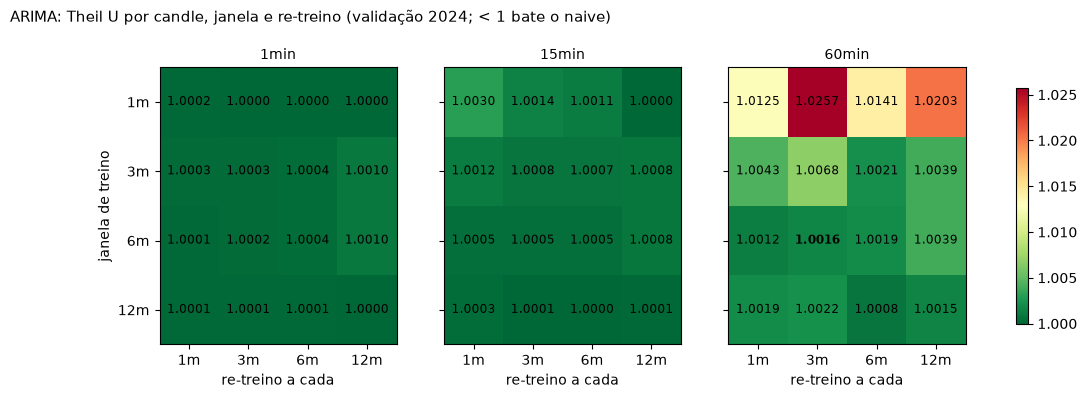

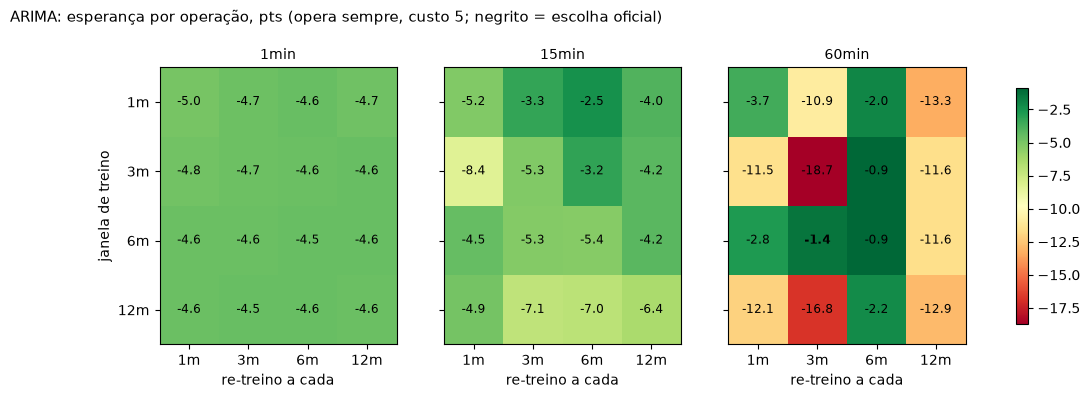

In [3]:
def heatmaps(coluna, titulo, arquivo, fmt, menor_melhor=False):
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
    vals = tab[coluna]
    vmin, vmax = vals.min(), vals.max()
    for ax, c in zip(axs, t.CANDLES):
        piv = tab[tab.candle == c].pivot(index="janela_meses", columns="retreino_meses", values=coluna)
        im = ax.imshow(piv.values, cmap="RdYlGn_r" if menor_melhor else "RdYlGn", aspect="auto", vmin=vmin, vmax=vmax)
        for i in range(piv.shape[0]):
            for j in range(piv.shape[1]):
                v = piv.values[i, j]
                ax.text(j, i, format(v, fmt), ha="center", va="center", fontsize=8.5,
                        weight="bold" if (piv.index[i], piv.columns[j]) == (6, 3) and c == "60min" else "normal")
        ax.set_xticks(range(piv.shape[1]), [f"{m}m" for m in piv.columns])
        ax.set_yticks(range(piv.shape[0]), [f"{m}m" for m in piv.index])
        ax.set_xlabel("re-treino a cada"); ax.set_title(c, fontsize=10)
    axs[0].set_ylabel("janela de treino")
    fig.suptitle(titulo, x=0.01, y=1.04, ha="left", fontsize=11)
    fig.colorbar(im, ax=axs, shrink=0.85)
    fig.savefig(arquivo, dpi=150, bbox_inches="tight"); plt.show()

heatmaps("TheilU", "ARIMA: Theil U por candle, janela e re-treino (validação 2024; < 1 bate o naive)",
         f"{SAIDA}/heatmap_theilU_retreino.png", ".4f", menor_melhor=True)
heatmaps("sim_esperanca_pts", "ARIMA: esperança por operação, pts (opera sempre, custo 5; negrito = escolha oficial)",
         f"{SAIDA}/heatmap_esperanca_retreino.png", ".1f")

In [4]:
oficial = tab[tab.retreino_meses == 3]
melhor = tab.sort_values(["sim_esperanca_pts", "TheilU"], ascending=[False, True]).iloc[0]
print(f"Theil U < 1 em {(tab.TheilU < 1).sum()} de {len(tab)} combinações (mínimo {tab.TheilU.min():.4f})")
print(f"Melhor das 48: {melhor.candle} × janela {int(melhor.janela_meses)}m × re-treino {int(melhor.retreino_meses)}m "
      f"→ {melhor.sim_esperanca_pts:.2f} ± {melhor.sim_ep_pts:.2f} pts/op")
o = oficial.sort_values("sim_esperanca_pts", ascending=False).iloc[0]
print(f"Melhor com re-treino trimestral (protocolo): {o.candle} × {int(o.janela_meses)}m → {o.sim_esperanca_pts:.2f} ± {o.sim_ep_pts:.2f}")

# efeito médio do re-treino, por candle (média sobre as 4 janelas)
efeito = tab.pivot_table(index="candle", columns="retreino_meses", values=["TheilU", "sim_esperanca_pts"], aggfunc="mean")
display(efeito.reindex(t.CANDLES).round(4))
# quanto o re-treino muda a esperança, comparado ao erro-padrão
amp = tab.groupby(["candle", "janela_meses"]).agg(amplitude=("sim_esperanca_pts", lambda s: s.max() - s.min()),
                                                  ep_medio=("sim_ep_pts", "mean"))
amp["amplitude_em_EPs"] = amp.amplitude / amp.ep_medio
display(amp.round(2))
tempo = tab.groupby(["candle", "retreino_meses"]).tempo_s.sum().unstack()
display(tempo)

Theil U < 1 em 2 de 48 combinações (mínimo 1.0000)
Melhor das 48: 60min × janela 6m × re-treino 6m → -0.89 ± 6.20 pts/op
Melhor com re-treino trimestral (protocolo): 60min × 6m → -1.44 ± 6.20


TheilU                         sim_esperanca_pts           \
retreino_meses      1       3       6       12                1        3    
candle                                                                      
1min            1.0002  1.0002  1.0002  1.0005           -4.7465  -4.6309   
15min           1.0012  1.0007  1.0006  1.0004           -5.7353  -5.2368   
60min           1.0050  1.0091  1.0047  1.0074           -7.5033 -11.9587   

                                 
retreino_meses      6        12  
candle                           
1min           -4.5782  -4.6102  
15min          -4.4931  -4.7084  
60min          -1.5051 -12.3358

amplitude  ep_medio  amplitude_em_EPs
candle janela_meses                                       
15min  1                  2.79      1.64              1.71
       3                  5.18      1.64              3.17
       6                  1.14      1.64              0.70
       12                 2.25      1.64              1.38
1min   1                  0.42      0.11              3.77
       3                  0.26      0.11              2.36
       6                  0.04      0.11              0.35
       12                 0.08      0.11              0.68
60min  1                 11.30      6.20              1.82
       3                 17.81      6.20              2.87
       6                 10.67      6.20              1.72
       12                14.60      6.20              2.35

retreino_meses,1,3,6,12
candle,,,,
15min,15.0,3.8,1.9,0.9
1min,147.5,43.9,19.0,9.2
60min,4.7,1.3,0.6,0.3


## Leitura

- **A frequência de re-treino não cria poder de previsão.** O Theil U fica entre 1,0000 e 1,026 nas 48 combinações. As duas "abaixo de 1" são 1,0000 arredondado, ou seja, empate com o naive. Re-estimar mais vezes não ajuda, porque os parâmetros do ARIMA são essencialmente ruído (φ ≈ −θ, Etapa G): re-estimá-los só troca um ruído por outro.
- **Não há padrão consistente.** Se re-treinar com mais frequência ajudasse, a coluna de 1 mês seria sistematicamente melhor, e não é. Em 60 min, a média do Theil U por re-treino é 1,0050 (1 m), 1,0091 (3 m), 1,0047 (6 m) e 1,0074 (12 m), sem tendência. As diferenças de esperança entre re-treinos para a mesma janela ficam entre 0,4 e 3,8 erros-padrão. Com 48 combinações, diferenças desse tamanho são esperadas por acaso.
- **A escolha oficial resiste.** A melhor das 48 é 60 min × janela 6 m × re-treino 6 m (−0,89 ± 6,2 pts/op), praticamente igual à oficial com re-treino trimestral (−1,44 ± 6,2). As duas continuam negativas, e 60 min × 6 m está entre as melhores em qualquer frequência, exceto 12 m.
- **O buraco nos dados aparece de novo.** Com re-treino de 12 meses há um único ajuste, em jan/2024, e nele as janelas de 3 e 6 meses usam os mesmos dados (começam em 17/10/2023). Por isso as duas linhas são idênticas nessa coluna (60 min: −11,56; 15 min: −4,21).
- **Custo computacional:** em 1 min, o re-treino mensal levou 144 s, contra 44 s no trimestral. Em 60 min a diferença é desprezível (6 s contra 1 s).
- **Recomendação:** manter o re-treino trimestral do protocolo. Na apresentação, a sensibilidade serve de argumento de robustez: "testamos re-treino de 1, 3, 6 e 12 meses e a conclusão não muda". Para o Random Forest e as redes, que têm muito mais parâmetros, a frequência pode importar mais; vale sugerir ao grupo.